## Burst analysis by run

This cell analyzes packet metadata exported by `tshark` for the client and onion-service Guards. For each of the five runs (`run_01`–`run_05`), it loads the CSV files, assigns a direction to each packet, and groups packets into bursts when they are close in time (initial threshold: 0.1 seconds) and have the same direction. The results are stored in `dataset_bursts`, separated by run and observation point, for use in subsequent matching analyses. Bursts are exploratory packet groupings, not verified matches to individual HTTP requests.

In [24]:
from pathlib import Path

import pandas as pd
import numpy as np

# 1. Configure Guard IP addresses for the new network
TARGET_IP_CLIENT = "10.5.184.229"
TARGET_IP_SERVICE = "10.5.237.145"
estimated_threshold = 0.1
runs = ["run_01", "run_02", "run_03", "run_04", "run_05"]

# Support execution from either the repository root or the experiment directory.
working_dir = Path.cwd().resolve()
results_candidates = [
    working_dir / "results",
    working_dir / "experiments" / "onion-correlation" / "results",
]
results_dir = next((path for path in results_candidates if path.is_dir()), None)
if results_dir is None:
    expected = " or ".join(str(path) for path in results_candidates)
    raise FileNotFoundError(
        f"Results directory not found. Current directory: {working_dir}. "
        f"Checked paths: {expected}"
    )
print(f"Results directory: {results_dir}")

# Dictionary for storing the DataFrames from all runs
dataset_bursts = {}

# 2. Loading and aggregation functions
def load_tshark_csv(csv_path, target_ip):
    df = pd.read_csv(csv_path)
    df.columns = ['timestamp', 'size', 'ip_src', 'ip_dst']
    df = df.dropna(subset=['ip_src', 'ip_dst'])
    # Direction: +1 (outgoing from the node), -1 (incoming to the node)
    df['direction'] = df['ip_src'].apply(lambda src: 1 if src == target_ip else -1)
    df = df.sort_values(by='timestamp').reset_index(drop=True)
    return df[['timestamp', 'size', 'direction']]

def calculate_bursts(df, time_threshold):
    df['delta_t'] = df['timestamp'].diff().fillna(0)
    time_condition = df['delta_t'] > time_threshold
    direction_condition = df['direction'] != df['direction'].shift()
    df['burst_id'] = (time_condition | direction_condition).cumsum()
    
    bursts = df.groupby('burst_id').agg(
        timestamp_start=('timestamp', 'min'),
        timestamp_end=('timestamp', 'max'),
        total_size=('size', 'sum'),
        direction=('direction', 'first'),
        packet_count=('size', 'count')
    ).reset_index()
    bursts['duration_sec'] = bursts['timestamp_end'] - bursts['timestamp_start']
    return bursts

# 3. Process all runs
for run_id in runs:
    print(f"--- Processing {run_id} ---")
    
    # Paths to the CSV files extracted with tshark
    run_analysis_dir = results_dir / run_id / "analysis" / "window_5s"
    csv_client = run_analysis_dir / "client_metadata.csv"
    csv_service = run_analysis_dir / "service_metadata.csv"
    missing_files = [path for path in (csv_client, csv_service) if not path.is_file()]
    if missing_files:
        missing = ", ".join(str(path) for path in missing_files)
        raise FileNotFoundError(
            f"Metadata files missing for {run_id}: {missing}. "
            "Generate the CSV files with tshark before running the notebook."
        )
    
    df_client = load_tshark_csv(csv_client, TARGET_IP_CLIENT)
    df_service = load_tshark_csv(csv_service, TARGET_IP_SERVICE)
    
    bursts_client = calculate_bursts(df_client, estimated_threshold)
    bursts_service = calculate_bursts(df_service, estimated_threshold)
    
    dataset_bursts[run_id] = {
        'client': bursts_client,
        'service': bursts_service
    }
    
    print(f"  -> Total client Guard bursts: {len(bursts_client)}")
    print(f"  -> Total service Guard bursts: {len(bursts_service)}\n")

if len(dataset_bursts) != len(runs):
    raise RuntimeError(f"Processed {len(dataset_bursts)} of {len(runs)} runs: dataset is incomplete.")
print(f"Aggregation complete: {len(dataset_bursts)} runs processed.")

Results directory: /home/elenapozzebon/tor-network-security-project/experiments/onion-correlation/results
--- Processing run_01 ---
  -> Total client Guard bursts: 1296
  -> Total service Guard bursts: 1135

--- Processing run_02 ---
  -> Total client Guard bursts: 2686
  -> Total service Guard bursts: 1256

--- Processing run_03 ---
  -> Total client Guard bursts: 2190
  -> Total service Guard bursts: 1152

--- Processing run_04 ---
  -> Total client Guard bursts: 1261
  -> Total service Guard bursts: 1820

--- Processing run_05 ---
  -> Total client Guard bursts: 1826
  -> Total service Guard bursts: 2026

Aggregation complete: 5 runs processed.


## Exploratory burst correlation

This section is divided into stages: configuration, client/server log validation, temporal attribution to request IDs, burst matching, and summary. Ground-truth logs are used to verify the actual requests. Run the cells from top to bottom, after the burst aggregation cell.


### 4.1 Parameters and initial checks

Define the exploratory thresholds used below: the allowed time interval between burst start times and the minimum burst size to include. The checks stop the analysis if the values are invalid or if the previous stage did not load any bursts.

In [25]:
# 4. Exploratory burst-correlation parameters
# These are provisional matching bounds, not calibrated detection thresholds.
MAX_LAG_BEFORE_SECONDS = 0.1
MAX_LAG_AFTER_SECONDS = 0.5
MINIMUM_BURST_SIZE = 1000

if MAX_LAG_BEFORE_SECONDS < 0 or MAX_LAG_AFTER_SECONDS < 0:
    raise ValueError("Matching time-window bounds must be non-negative.")
if MINIMUM_BURST_SIZE < 0:
    raise ValueError("MINIMUM_BURST_SIZE must be non-negative.")
if not dataset_bursts:
    raise ValueError("No burst data is available to correlate.")



### 4.2 Loading and validating ground truth

For each run, compare requests in the client CSV with HTTP accesses in the server log. Server-log timestamps are in UTC and have one-second precision, so each entry must overlap exactly one client request interval. HTTP status codes are checked as well; ambiguous alignments, unmatched entries, or successful requests without a server access raise an explicit error.

In [26]:
import re
from datetime import datetime, timezone

SERVER_ACCESS_PATTERN = re.compile(
    r"\[(\d{2}/[A-Za-z]{3}/\d{4} \d{2}:\d{2}:\d{2})\] "
    r"\"GET / HTTP/1\.1\" (\d{3})"
)

def load_confirmed_requests(run_id):
    """Align client requests with second-resolution UTC server log entries."""
    run_dir = results_dir / run_id
    request_path = run_dir / "client_requests_log.csv"
    server_log_path = run_dir / "server_access.log"
    missing_paths = [path for path in (request_path, server_log_path) if not path.is_file()]
    if missing_paths:
        raise FileNotFoundError(
            f"Request ground-truth files missing for {run_id}: "
            + ", ".join(str(path) for path in missing_paths)
        )

    requests = pd.read_csv(request_path)
    required_columns = {
        "request_id", "timestamp_start", "timestamp_end", "status_code", "success"
    }
    missing_columns = required_columns.difference(requests.columns)
    if missing_columns:
        raise ValueError(
            f"Request log for {run_id} is missing columns: {sorted(missing_columns)}"
        )
    if requests["request_id"].duplicated().any():
        raise ValueError(f"Request IDs are not unique in {request_path}")

    log_text = server_log_path.read_text(encoding="utf-8", errors="replace")
    server_events = [
        (
            datetime.strptime(timestamp, "%d/%b/%Y %H:%M:%S")
            .replace(tzinfo=timezone.utc)
            .timestamp(),
            int(status),
        )
        for timestamp, status in SERVER_ACCESS_PATTERN.findall(log_text)
    ]

    used_events = set()
    confirmed_request_ids = set()
    for _, request in requests.iterrows():
        start = float(request["timestamp_start"])
        end = float(request["timestamp_end"])
        overlapping_events = [
            event_index
            for event_index, (event_start, _) in enumerate(server_events)
            if event_start < end and event_start + 1 > start
        ]
        request_id = int(request["request_id"])
        if len(overlapping_events) > 1:
            raise RuntimeError(
                f"{run_id} request {request_id} overlaps multiple server log entries."
            )
        if not overlapping_events:
            if bool(request["success"]):
                raise RuntimeError(
                    f"Successful request {request_id} in {run_id} has no "
                    "overlapping server access entry."
                )
            continue

        event_index = overlapping_events[0]
        if event_index in used_events:
            raise RuntimeError(
                f"A server access entry is associated with multiple requests in {run_id}."
            )
        used_events.add(event_index)
        server_status = server_events[event_index][1]
        if bool(request["success"]):
            if pd.isna(request["status_code"]) or server_status != int(request["status_code"]):
                raise RuntimeError(
                    f"Client/server HTTP status mismatch for request {request_id} in {run_id}."
                )
            confirmed_request_ids.add(request_id)

    if len(used_events) != len(server_events):
        raise RuntimeError(
            f"{run_id} has {len(server_events) - len(used_events)} server access "
            "entries that do not align with a client request."
        )
    return requests, confirmed_request_ids, len(server_events)



### 4.3 Attributing bursts to requests

This function assigns a burst start time to a confirmed request ID only when it falls within exactly one time window: the client interval expanded by the tolerances defined above. If the window is ambiguous, the analysis stops rather than assigning an arbitrary ID.

In [27]:
def attribute_burst_to_request(timestamp, request_windows):
    """Return a unique confirmed request ID for a burst start, if one exists."""
    matching_ids = [
        request_id
        for request_id, window_start, window_end in request_windows
        if window_start <= float(timestamp) <= window_end
    ]
    if len(matching_ids) > 1:
        raise RuntimeError(
            f"Burst timestamp {timestamp} falls in multiple request windows: {matching_ids}"
        )
    return matching_ids[0] if matching_ids else None



### 4.4 Greedy one-to-one temporal matching

For each client burst, in chronological order, find the still-available service bursts within the allowed window and choose the temporally closest one. Each service burst can be used only once. This is a simple greedy heuristic: a local choice may not produce the globally largest number of pairs.


In [28]:
def match_bursts_one_to_one(client_bursts, service_bursts):
    """Greedily pair each client burst with its nearest eligible service burst."""
    clients = client_bursts.sort_values(
        "timestamp_start", kind="mergesort"
    ).reset_index(drop=True)
    unmatched_services = service_bursts.sort_values(
        "timestamp_start", kind="mergesort"
    ).copy()

    pairs = []
    for _, client in clients.iterrows():
        client_start = client["timestamp_start"]
        service_lags = unmatched_services["timestamp_start"] - client_start
        candidates = unmatched_services.loc[
            service_lags.between(
                -MAX_LAG_BEFORE_SECONDS,
                MAX_LAG_AFTER_SECONDS,
                inclusive="both",
            )
        ]
        if candidates.empty:
            continue

        lag = candidates["timestamp_start"] - client_start
        service_index = lag.abs().idxmin()
        service = candidates.loc[service_index]
        pairs.append(
            {
                "client_burst": client,
                "service_burst": service,
                "lag_seconds": float(service["timestamp_start"] - client_start),
            }
        )
        unmatched_services = unmatched_services.drop(service_index)

    return pairs


### 4.5 Analyzing each run

For each run, filter out small bursts, perform the matching, and load the ground-truth logs. Then attribute bursts to confirmed request windows and count pairs whose two bursts fall within the same window. Request-level coverage counts distinct IDs represented at least once; burst-level coverage and lag values remain separate diagnostics.

In [29]:
correlation_results = {}

print(
    "Starting exploratory burst matching with lag bounds "
    f"[-{MAX_LAG_BEFORE_SECONDS}, +{MAX_LAG_AFTER_SECONDS}]s "
    f"and minimum burst size={MINIMUM_BURST_SIZE} bytes\n"
)

for run_id, run_data in dataset_bursts.items():
    client_bursts = run_data["client"]
    service_bursts = run_data["service"]

    relevant_client = client_bursts.loc[
        client_bursts["total_size"] >= MINIMUM_BURST_SIZE
    ].copy()
    relevant_service = service_bursts.loc[
        service_bursts["total_size"] >= MINIMUM_BURST_SIZE
    ].copy()
    matched_pairs = match_bursts_one_to_one(relevant_client, relevant_service)
    request_log, confirmed_request_ids, server_access_count = load_confirmed_requests(run_id)
    request_windows = [
        (
            int(request["request_id"]),
            float(request["timestamp_start"]) - MAX_LAG_BEFORE_SECONDS,
            float(request["timestamp_end"]) + MAX_LAG_AFTER_SECONDS,
        )
        for _, request in request_log.iterrows()
        if int(request["request_id"]) in confirmed_request_ids
    ]
    same_request_pairs = []
    for pair in matched_pairs:
        pair["client_request_id"] = attribute_burst_to_request(
            pair["client_burst"]["timestamp_start"], request_windows
        )
        pair["service_request_id"] = attribute_burst_to_request(
            pair["service_burst"]["timestamp_start"], request_windows
        )
        client_request_id = pair["client_request_id"]
        service_request_id = pair["service_request_id"]
        if client_request_id is not None and client_request_id == service_request_id:
            same_request_pairs.append(pair)
    recovered_request_ids = {
        pair["client_request_id"] for pair in same_request_pairs
    }
    matched_pair_count = len(matched_pairs)
    client_coverage = (
        100 * matched_pair_count / len(relevant_client) if len(relevant_client) else None
    )
    service_coverage = (
        100 * matched_pair_count / len(relevant_service) if len(relevant_service) else None
    )
    lags = [pair["lag_seconds"] for pair in matched_pairs]

    correlation_results[run_id] = {
        "matched_burst_pairs": matched_pair_count,
        "client_burst_coverage_pct": client_coverage,
        "service_burst_coverage_pct": service_coverage,
        "relevant_client_bursts": len(relevant_client),
        "relevant_service_bursts": len(relevant_service),
        "client_requests": len(request_log),
        "confirmed_requests": len(confirmed_request_ids),
        "server_access_records": server_access_count,
        "same_request_window_pairs": len(same_request_pairs),
        "recovered_request_ids": recovered_request_ids,
        "matched_pairs": matched_pairs,
    }

    print(f"[{run_id.upper()}]")
    print(
        f"  -> Filtered bursts (client): {len(relevant_client)} | "
        f"(service): {len(relevant_service)}"
    )
    print(f"  -> One-to-one candidate burst pairs: {matched_pair_count}")
    print(
        f"  -> Requests confirmed by client/server logs: "
        f"{len(confirmed_request_ids)}/{len(request_log)} client records; "
        f"{server_access_count} server access records"
    )
    if matched_pair_count:
        pair_consistency = 100 * len(same_request_pairs) / matched_pair_count
        print(
            f"  -> Same-request-window-consistent pairs: "
            f"{len(same_request_pairs)}/{matched_pair_count} "
            f"({pair_consistency:.1f}%; heuristic, not precision)"
        )
    else:
        print("  -> Same-request-window-consistent pairs: 0/0 (n/a)")
    request_coverage = (
        100 * len(recovered_request_ids) / len(confirmed_request_ids)
        if confirmed_request_ids
        else None
    )
    if request_coverage is not None:
        print(
            f"  -> Confirmed requests represented by >=1 consistent pair: "
            f"{len(recovered_request_ids)}/{len(confirmed_request_ids)} "
            f"({request_coverage:.1f}% request-window coverage)"
        )
    else:
        print("  -> Confirmed request-window coverage: n/a")
    if client_coverage is not None:
        print(f"  -> Client filtered-burst coverage: {client_coverage:.1f}%")
    else:
        print("  -> Client filtered-burst coverage: n/a")
    if service_coverage is not None:
        print(f"  -> Service burst coverage: {service_coverage:.1f}%")
    else:
        print("  -> Service burst coverage: n/a")
    if lags:
        print(
            f"  -> Start-time lag (service - client), median / p95: "
            f"{np.median(lags):.3f}s / {np.percentile(lags, 95):.3f}s\n"
        )
    else:
        print("  -> No candidate pairs; lag statistics unavailable.\n")



Starting exploratory burst matching with lag bounds [-0.1, +0.5]s and minimum burst size=1000 bytes

[RUN_01]
  -> Filtered bursts (client): 179 | (service): 173
  -> One-to-one candidate burst pairs: 167
  -> Requests confirmed by client/server logs: 100/100 client records; 100 server access records
  -> Same-request-window-consistent pairs: 167/167 (100.0%; heuristic, not precision)
  -> Confirmed requests represented by >=1 consistent pair: 82/100 (82.0% request-window coverage)
  -> Client filtered-burst coverage: 93.3%
  -> Service burst coverage: 96.5%
  -> Start-time lag (service - client), median / p95: -0.004s / -0.002s

[RUN_02]
  -> Filtered bursts (client): 413 | (service): 199
  -> One-to-one candidate burst pairs: 177
  -> Requests confirmed by client/server logs: 100/100 client records; 100 server access records
  -> Same-request-window-consistent pairs: 173/177 (97.7%; heuristic, not precision)
  -> Confirmed requests represented by >=1 consistent pair: 83/100 (83.0% re

### 4.6 Overall summary

Sum the pairs and filtered bursts across all runs, calculate pooled coverage, and summarize the lags. Pairs consistent with a request window are not precision: the window is provisional, and multiple pairs may represent the same request.

In [30]:
total_matched = sum(
    result["matched_burst_pairs"] for result in correlation_results.values()
)
total_client_bursts = sum(
    result["relevant_client_bursts"] for result in correlation_results.values()
)
total_service_bursts = sum(
    result["relevant_service_bursts"] for result in correlation_results.values()
)
all_lags = [
    pair["lag_seconds"]
    for result in correlation_results.values()
    for pair in result["matched_pairs"]
]
total_confirmed_requests = sum(
    result["confirmed_requests"] for result in correlation_results.values()
)
total_same_request_pairs = sum(
    result["same_request_window_pairs"] for result in correlation_results.values()
)
total_recovered_requests = sum(
    len(result["recovered_request_ids"]) for result in correlation_results.values()
)
print("-" * 40)
print(f"Pooled candidate burst pairs: {total_matched}")
if total_client_bursts:
    print(
        "Pooled client filtered-burst coverage: "
        f"{100 * total_matched / total_client_bursts:.1f}%"
    )
else:
    print("Pooled client filtered-burst coverage: n/a")
if total_service_bursts:
    print(
        "Pooled service filtered-burst coverage: "
        f"{100 * total_matched / total_service_bursts:.1f}%"
    )
else:
    print("Pooled service filtered-burst coverage: n/a")
if all_lags:
    print(
        f"Pooled start-time lag median / p95 (service - client): "
        f"{np.median(all_lags):.3f}s / {np.percentile(all_lags, 95):.3f}s"
    )
if total_matched:
    print(
        "Pooled same-request-window-consistent pairs: "
        f"{total_same_request_pairs}/{total_matched} "
        f"({100 * total_same_request_pairs / total_matched:.1f}%; heuristic, not precision)"
    )
if total_confirmed_requests:
    print(
        "Pooled confirmed requests represented by >=1 consistent pair: "
        f"{total_recovered_requests}/{total_confirmed_requests} "
        f"({100 * total_recovered_requests / total_confirmed_requests:.1f}% "
        "request-window coverage)"
    )
print("Request attribution uses provisional time windows; it is not causal proof.")

----------------------------------------
Pooled candidate burst pairs: 874
Pooled client filtered-burst coverage: 58.0%
Pooled service filtered-burst coverage: 63.5%
Pooled start-time lag median / p95 (service - client): -0.001s / 0.003s
Pooled same-request-window-consistent pairs: 870/874 (99.5%; heuristic, not precision)
Pooled confirmed requests represented by >=1 consistent pair: 429/500 (85.8% request-window coverage)
Request attribution uses provisional time windows; it is not causal proof.


## Visualizing the results

The following plots summarize the lag distribution of burst pairs and the number of requests represented in each run. The second measure is request-window coverage under the selected heuristic; it is not equivalent to deanonymized requests, precision, or attack reliability.


### Lag distribution for matched bursts

The histogram shows `service timestamp - client timestamp` for all candidate pairs. The dashed line marks zero lag. A concentration near zero indicates temporal proximity in the dataset, but does not by itself prove that the bursts were caused by the same request.


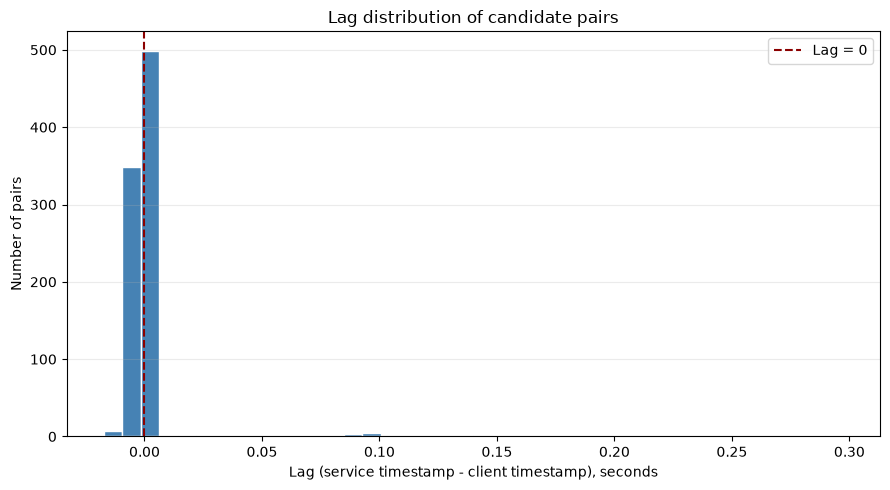

In [31]:
import matplotlib.pyplot as plt

all_lags = [
    pair["lag_seconds"]
    for result in correlation_results.values()
    for pair in result["matched_pairs"]
]

if all_lags:
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.hist(all_lags, bins=40, color="steelblue", edgecolor="white")
    ax.axvline(0, color="darkred", linestyle="--", label="Lag = 0")
    ax.set_title("Lag distribution of candidate pairs")
    ax.set_xlabel("Lag (service timestamp - client timestamp), seconds")
    ax.set_ylabel("Number of pairs")
    ax.grid(axis="y", alpha=0.25)
    ax.legend()
    fig.tight_layout()
    plt.show()
else:
    print("No candidate pairs; lag histogram is unavailable.")


### Confirmed requests and temporal coverage by run

Compare requests confirmed by the client/server logs with requests represented by at least one burst pair attributed to the same window. Represented requests are a heuristic result that depends on the time windows; they are not requests proven to have been deanonymized.


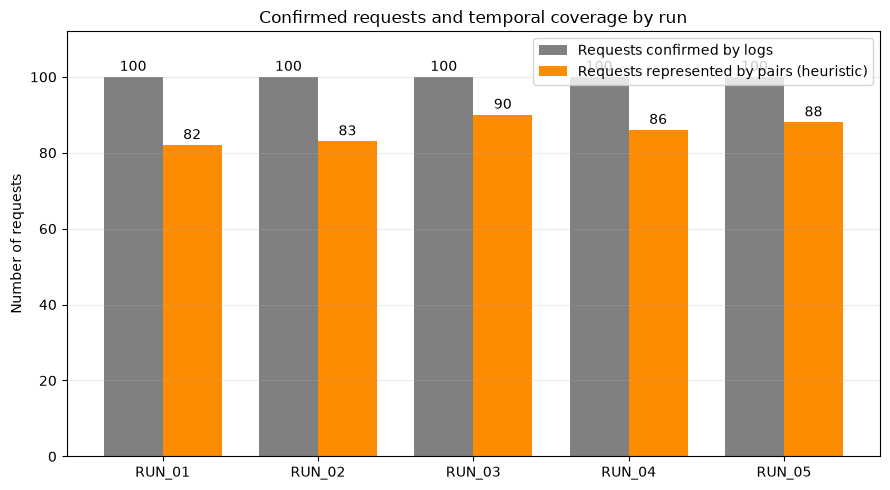

In [32]:
run_ids = sorted(correlation_results)
confirmed_counts = [
    correlation_results[run_id]["confirmed_requests"]
    for run_id in run_ids
]
represented_counts = [
    len(correlation_results[run_id]["recovered_request_ids"])
    for run_id in run_ids
]
positions = np.arange(len(run_ids))
bar_width = 0.38

fig, ax = plt.subplots(figsize=(9, 5))
confirmed_bars = ax.bar(
    positions - bar_width / 2,
    confirmed_counts,
    bar_width,
    label="Requests confirmed by logs",
    color="gray",
)
represented_bars = ax.bar(
    positions + bar_width / 2,
    represented_counts,
    bar_width,
    label="Requests represented by pairs (heuristic)",
    color="darkorange",
)
ax.bar_label(confirmed_bars, padding=2)
ax.bar_label(represented_bars, padding=2)
ax.set_xticks(positions, [run_id.upper() for run_id in run_ids])
ax.set_ylim(0, max(confirmed_counts, default=0) * 1.12)
ax.set_ylabel("Number of requests")
ax.set_title("Confirmed requests and temporal coverage by run")
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()
